In [3]:
ROLL_NO = 1024170448       # <-- your full roll number
NAME = "RhythmKapila"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

In [4]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)
    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

In [5]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords
STOP = set(stopwords.words("english"))
def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [6]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170448   Name: RhythmKapila   Fingerprint: 490A65EA   Tickets: 15

Ticket_ID                                                                                       Ticket_Text
      T01                                                                   Is it fixed?? Pls reply ASAP :(
      T02                               Printer is not working after restarting the system. This is urgent.
      T03                           I tried restarting the printer on my laptop. I don't know what changed.
      T04 I keep getting logged out of the projector after the latest update. It works on another computer.
      T05                                                     The projector failed to open. This is urgent.
      T06                                                                    Error code 0x80070005 appears.
      T07                                The student portal is showing an error. Is there another solution?
      T08                                           

In [7]:
import pandas as pd
# Ensure 'df' is generated if it hasn't been executed yet
try:
    df
except NameError:
    df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)

tickets = df['Ticket_Text'].tolist()
data = []

for i, ticket in enumerate(tickets):
    # Run process_ticket on the current ticket
    res = process_ticket(ticket)

    # Extract counts / lengths based on official preprocessing outputs
    data.append({
        "Ticket ID": f"T{i + 1:02d}",
        "Sentences": len(res.get("sentences", [])),
        "Tokens": len(res.get("tokens", [])),
        "Punctuation Tokens": len(res.get("punct", [])),
        "Stopwords": len(res.get("stops", [])),
        "Unique Tokens": len(set(res.get("tokens", []))),
        "Final Tokens": len(res.get("final", []))
    })

# Create DataFrame
summary_df = pd.DataFrame(data)
# Add a TOTAL row for the count-based columns
total_row = pd.DataFrame({
    "Ticket ID": ["TOTAL"],
    "Sentences": [summary_df["Sentences"].sum()],
    "Tokens": [summary_df["Tokens"].sum()],
    "Punctuation Tokens": [summary_df["Punctuation Tokens"].sum()],
    "Stopwords": [summary_df["Stopwords"].sum()],
    "Unique Tokens": [summary_df["Unique Tokens"].sum()],
    "Final Tokens": [summary_df["Final Tokens"].sum()]
})

summary_df = pd.concat([summary_df, total_row], ignore_index=True)
display(summary_df)

# Display tokens for one selected ticket (e.g., the first ticket)
sample_idx = 0
print(f"\n--- Detailed Tokens for Ticket T{sample_idx + 1:02d} ---")
sample_res = process_ticket(tickets[sample_idx])
print("Tokens:", sample_res.get("tokens"))
print("Punctuation:", sample_res.get("punct"))
print("Stopwords:", sample_res.get("stops"))
print("Final Tokens:", sample_res.get("final"))

,Ticket ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,10,4,2,9,4
1,T02,2,13,2,6,11,5
2,T03,2,16,2,7,14,7
3,T04,2,19,2,8,17,9
4,T05,2,10,2,4,9,4
5,T06,1,5,1,0,5,4
6,T07,2,13,2,5,12,6
7,T08,1,7,1,2,7,4
8,T09,2,12,2,3,11,7
9,T10,2,11,2,4,9,5



--- Detailed Tokens for Ticket T01 ---
Tokens: ['is', 'it', 'fixed', '?', '?', 'pls', 'reply', 'asap', ':', '(']
Punctuation: ['?', '?', ':', '(']
Stopwords: ['is', 'it']
Final Tokens: ['fixed', 'pls', 'reply', 'asap']


In [9]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re
# Given test lines from the assignment notebook
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5 done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

print("=== 1. Extractions using re.findall ===")
for i, line in enumerate(TEST_LINES):
  print(f"\n--- Line {i+1} ---")
  # Words longer than 5 letters
  long_words = re.findall(r"\b[a-zA-Z]{6,}\b", line)
  print("Words > 5 letters:", long_words)

  # All numbers (keeping decimals and version numbers like 95.5 and 2.0.1 whole)
  numbers = re.findall(r"\b\d+(?:[\.,]\d+)*\b", line)
  print("Numbers:", numbers)

  # Capitalized words
  cap_words = re.findall(r"\b[A-Z][a-z]*\b", line)
  print("Capitalized words:", cap_words)

  # Words starting with a vowel
  vowel_words = re.findall(r"\b[aeiouAEIOU]\w*\b", line)
  print("Words starting with a vowel:", vowel_words)


print("\n=== 2. Replacements using re.sub ===")
# Regex patterns for emails, URLs, and phone numbers
email_pattern = r"[\w\.-]+@[\w\.-]+\.\w+"
url_pattern = r"https?://[^\s]+|www\.[^\s]+"
phone_pattern = r"(?:\+?\d{1,3}[-.\s]?)??\d2,4?[-.\s]?\d{3,5}[-.\s]?\d{4}"

for i, line in enumerate(TEST_LINES):
  # Replace emails with ',', URLs with '', and phone numbers with '.'
  cleaned = re.sub(email_pattern, ",", line)
  cleaned = re.sub(url_pattern, "", cleaned)
  cleaned = re.sub(phone_pattern, ".", cleaned)
  print(f"Line {i+1} cleaned:", cleaned)

=== 1. Extractions using re.findall ===

--- Line 1 ---
Words > 5 letters: ['helpdesk', 'thapar', 'thapar', 'thapar']
Numbers: []
Capitalized words: ['Mail']
Words starting with a vowel: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']

--- Line 2 ---
Words > 5 letters: ['Version']
Numbers: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250']
Capitalized words: ['Call', 'Version', 'Rs']
Words starting with a vowel: ['or', 'is']

--- Line 3 ---
Words > 5 letters: []
Numbers: ['5.30']
Capitalized words: ['The']
Words starting with a vowel: ['of', 'art', 'isn', 'open', 'in', 'at']

=== 2. Replacements using re.sub ===
Line 1 cleaned: Mail , or ,; visit  or 
Line 2 cleaned: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5 done; fee Rs 1,250.
Line 3 cleaned: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.


In [10]:
import re
from nltk.tokenize import RegexpTokenizer, word_tokenize

# Define the single regex pattern matching all requested entities in order of priority:
# 1. URLs (http/https or www)
# 2. Email addresses
# 3. Phone numbers (e.g., +91 98765 43210 or 0175-239-3201)
# 4. Decimals and Version numbers (e.g., 95.5, 2.0.1) or standalone numbers
# 5. Contractions and Hyphenated words (e.g., isn't, state-of-the-art, Wi-Fi)
# 6. Any other remaining word tokens or single punctuation characters
pattern = r'''(?x)
    https?://[^\s;,]+|www\.[^\s;,]+                      # URLs
  | [\w\.-]+@[\w\.-]+\.\w+                              # Emails
  | \+?\d{1,3}[-.\s]?\d{2,5}[-.\s]?\d{3,5}(?:[-.\s]?\d{4})? # Phone numbers
  | \d+(?:\.\d+)+%?                                     # Decimals & Version numbers (e.g., 95.5, 2.0.1)
  | \b\w+(?:['’-]\w+)*\b                                # Contractions & Hyphenated words
  | \w+                                                 # Regular words
  | [^\w\s]                                             # Individual punctuation marks
'''

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

# --- Test on TEST_LINES ---
print("=== Testing on TEST_LINES ===")
for i, line in enumerate(TEST_LINES):
    custom_toks = my_tokenize(line)
    nltk_toks = word_tokenize(line)

    print(f"\n--- Line {i+1} ---")
    print("my_tokenize  :", custom_toks)
    print("word_tokenize:", nltk_toks)

# --- Run on tickets and compare ---
differing_tickets_count = 0

for i, ticket in enumerate(tickets):
    custom_toks = my_tokenize(ticket)
    nltk_toks = word_tokenize(ticket)

    if custom_toks != nltk_toks:
        differing_tickets_count += 1

print(f"\nTotal tickets tokenized differently: {differing_tickets_count} out of {len(tickets)}")


=== Testing on TEST_LINES ===

--- Line 1 ---
my_tokenize  : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

--- Line 2 ---
my_tokenize  : ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', 'done', ';', 'fee', 'Rs', '1,250', '.']

--- Line 3 ---
my_tokenize  : ['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']
word_tokenize: ['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.

In [11]:
import pandas as pd
import nltk
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

# Ensure required NLTK resources are available
nltk.download('punkt', quiet=True)
nltk.download('averaged_perceptron_tagger', quiet=True)
nltk.download('wordnet', quiet=True)

# Helper function to map NLTK POS tag to WordNet POS tag
def get_wordnet_pos(treebank_tag):
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

# Initialize stemmers and lemmatizer
porter = PorterStemmer()
lancaster = LancasterStemmer()
# Custom RegexpStemmer (e.g., removing common IT support suffixes like 'ing', 'ed', 'ly', 's')
regexp_stemmer = RegexpStemmer('ing|ed|ly|s', min=4)
lemmatizer = WordNetLemmatizer()

# Gather unique final tokens across all tickets
unique_final_tokens = set()
for ticket in tickets:
    # Assuming `process_ticket` or your custom tokenizer produces final tokens
    res = process_ticket(ticket)
    tokens = res.get("final_tokens", [])
    unique_final_tokens.update(tokens)

unique_final_tokens = sorted(list(unique_final_tokens))

# Compare outputs
comparison_data = []

# Tag POS for all tokens
tagged_tokens = nltk.pos_tag(unique_final_tokens)

for word, tag in tagged_tokens:
    p_stem = porter.stem(word)
    l_stem = lancaster.stem(word)
    r_stem = regexp_stemmer.stem(word)

    wn_pos = get_wordnet_pos(tag)
    lemma = lemmatizer.lemmatize(word, pos=wn_pos)

    # Check if outputs differ among the methods
    outputs = {p_stem, l_stem, r_stem, lemma, word.lower()}
    if len(outputs) > 1:
        comparison_data.append({
            "Token": word,
            "POS": tag,
            "Porter": p_stem,
            "Lancaster": l_stem,
            "Regexp": r_stem,
            "Lemmatizer": lemma
        })

df_diff = pd.DataFrame(comparison_data)
display(df_diff)

""


=== Corpus Statistics Table ===


,Corpus,Total Tokens,Unique Tokens,TTR
0,S1 (All tokens),181,87,0.4807
1,S2 (No punctuation),181,87,0.4807
2,S3 (Final tokens),0,0,0.0000
3,S4 (S3 after Porter),0,0,0.0000



Top 10 words of S1:
[('.', 23), ('the', 12), ('is', 8), ('it', 5), ('i', 5), ('on', 5), ('another', 5), ('?', 4), ('after', 4), ('works', 4)]

Top 10 words of S3:
[]


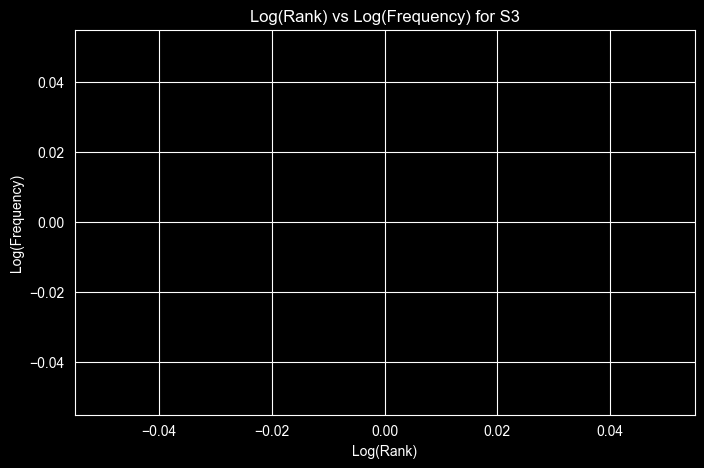


Top 5 bigrams of S1:
[(('.', 'i'), 4), (('.', 'it'), 4), (('.', 'this'), 3), (('this', 'is'), 3), (('is', 'urgent'), 3)]

Top 5 bigrams of S3:
[]


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from nltk import bigrams
from nltk.stem import PorterStemmer

# Collect tokens from all tickets based on definitions:
# S1: All tokens (including punctuation and stopwords)
# S2: No punctuation (tokens excluding punctuation)
# S3: Final tokens (after removing punctuation, stopwords, etc.)
# S4: S3 after Porter stemming

s1_tokens = []
s2_tokens = []
s3_tokens = []
porter = PorterStemmer()

for ticket in tickets:
    res = process_ticket(ticket)

    # Assuming standard keys from pipeline outputs
    t_all = res.get("tokens", [])
    t_punct = res.get("punctuation", [])
    t_final = res.get("final_tokens", [])

    s1_tokens.extend(t_all)
    # S2: tokens excluding punctuation
    s2_tokens.extend([t for t in t_all if t not in t_punct])
    s3_tokens.extend(t_final)

s4_tokens = [porter.stem(token) for token in s3_tokens]

# Function to calculate corpus statistics
def get_stats(token_list, name):
    total_tokens = len(token_list)
    unique_tokens = len(set(token_list))
    ttr = unique_tokens / total_tokens if total_tokens > 0 else 0
    return {
        "Corpus": name,
        "Total Tokens": total_tokens,
        "Unique Tokens": unique_tokens,
        "TTR": round(ttr, 4)
    }

stats_summary = [
    get_stats(s1_tokens, "S1 (All tokens)"),
    get_stats(s2_tokens, "S2 (No punctuation)"),
    get_stats(s3_tokens, "S3 (Final tokens)"),
    get_stats(s4_tokens, "S4 (S3 after Porter)")
]

df_stats = pd.DataFrame(stats_summary)
print("=== Corpus Statistics Table ===")
display(df_stats)

# Print top 10 words of S1 and S3
print("\nTop 10 words of S1:")
print(Counter(s1_tokens).most_common(10))

print("\nTop 10 words of S3:")
print(Counter(s3_tokens).most_common(10))

# Plot log(rank) vs log(frequency) for S3
s3_counts = Counter(s3_tokens)
frequencies = sorted([count for word, count in s3_counts.most_common()], reverse=True)
ranks = range(1, len(frequencies) + 1)

log_ranks = np.log(ranks)
log_freqs = np.log(frequencies)

plt.figure(figsize=(8, 5))
plt.plot(log_ranks, log_freqs, marker='o', linestyle='-')
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.xlabel("Log(Rank)")
plt.ylabel("Log(Frequency)")
plt.grid(True)
plt.show()

# Print top 5 bigrams of S1 and S3
s1_bigrams = list(bigrams(s1_tokens))
s3_bigrams = list(bigrams(s3_tokens))

print("\nTop 5 bigrams of S1:")
print(Counter(s1_bigrams).most_common(5))

print("\nTop 5 bigrams of S3:")
print(Counter(s3_bigrams).most_common(5))

In [13]:
print(" ASSIGNMENT 7 COMPLETE :)")

 ASSIGNMENT 7 COMPLETE :)
